# Chapter 14 · Short-rate models: interactive demos

Companion to Chapter 14 of the [IEOR 222 lecture notes](https://gennaroalberto.github.io/ieor222-financial-engineering/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/ieor222-financial-engineering/blob/main/code/notebooks/14-rates.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

All models are written under the risk-neutral measure $\mathbb Q$. The Vasicek rate is
$dr_t=\kappa(\theta-r_t)\,dt+\sigma\,d\widetilde W_t$, the CIR rate
$dr_t=\kappa(\theta-r_t)\,dt+\sigma\sqrt{r_t}\,d\widetilde W_t$, and the bond price is
$P(t,T)=\mathbb E^{\mathbb Q}[e^{-\int_t^Tr_u\,du}\mid\mathcal F_t]=e^{A(T-t)-B(T-t)r_t}$ in both (Theorem 14.5).

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/ieor222-financial-engineering#subdirectory=code"

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gamma as gamma_law
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown

from ieor222.rates import (cir_bond, cir_euler, cir_exact, cir_long_yield, cir_stationary, cir_yield,
                           feller_ratio, integrated_rate, mc_bond_prices, vasicek_bond, vasicek_bond_option,
                           vasicek_euler, vasicek_exact, vasicek_forward, vasicek_forward_measure_rT,
                           vasicek_long_yield, vasicek_mean, vasicek_negative_prob, vasicek_shape_thresholds,
                           vasicek_yield, yields)
from ieor222.style import COBALT, GOLD, GREY, INK, PALETTE, use_style

GREEN = PALETTE[2]
use_style()
plt.rcParams["figure.dpi"] = 90

## 1. Yield curves

For three starting values of the short rate, the Vasicek and CIR yield curves $\tau\mapsto Y(t,t+\tau)$
(Propositions 14.8 and 14.9). The CIR volatility is chosen so that both models have the same volatility of
rates at $r=\theta$: $\sigma_{\rm CIR}\sqrt\theta=\sigma$. Vasicek (1977) showed that his yield curve is increasing
when $r_t\le R_\infty-\sigma^2/(4\kappa^2)$, decreasing when $r_t\ge R_\infty+\sigma^2/(2\kappa^2)$, and humped in
between, where $R_\infty=\theta-\sigma^2/(2\kappa^2)$ is the long yield; the title prints these thresholds.

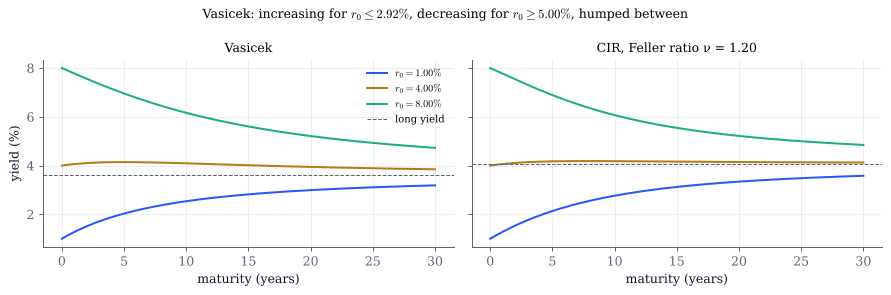

In [2]:
def curves(r_mid=0.04, kappa=0.15, theta=0.05, sigma=0.025, horizon=30):
    tau = np.linspace(0, horizon, 301)
    s_cir = sigma / np.sqrt(theta)
    lo, hi = vasicek_shape_thresholds(kappa, theta, sigma)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.3), sharey=True)
    for ax, name in zip(axes, ("Vasicek", "CIR")):
        for r0, c in ((0.01, COBALT), (r_mid, GOLD), (0.08, GREEN)):
            y = vasicek_yield(r0, tau, kappa, theta, sigma) if name == "Vasicek" else cir_yield(r0, tau, kappa, theta, s_cir)
            ax.plot(tau, 100 * y, color=c, label=f"$r_0={100 * r0:.2f}\\%$")
        R = vasicek_long_yield(kappa, theta, sigma) if name == "Vasicek" else cir_long_yield(kappa, theta, s_cir)
        ax.axhline(100 * R, color=GREY, lw=0.8, ls="--", label="long yield")
        ax.set(xlabel="maturity (years)", title=name if name == "Vasicek" else
               f"CIR, Feller ratio ν = {feller_ratio(kappa, theta, s_cir):.2f}")
    axes[0].set_ylabel("yield (%)")
    axes[0].legend(fontsize=8)
    fig.suptitle(f"Vasicek: increasing for $r_0\\leq{100 * lo:.2f}\\%$, decreasing for $r_0\\geq{100 * hi:.2f}\\%$, humped between", fontsize=10)
    fig.tight_layout()
    plt.show()

curves()

In [3]:
# Explore: move the middle starting rate through the humped range; raise sigma and watch the long yields fall.
interact(curves,
         r_mid=FloatSlider(value=0.04, min=-0.02, max=0.1, step=0.0025, continuous_update=False, readout_format=".4f", description="r₀ (middle)"),
         kappa=FloatSlider(value=0.15, min=0.02, max=2.0, step=0.01, continuous_update=False, description="κ"),
         theta=FloatSlider(value=0.05, min=0.005, max=0.1, step=0.005, continuous_update=False, readout_format=".3f", description="θ"),
         sigma=FloatSlider(value=0.025, min=0.002, max=0.06, step=0.001, continuous_update=False, readout_format=".3f", description="σ"),
         horizon=IntSlider(value=30, min=5, max=100, step=5, continuous_update=False, description="horizon"));

## 2. Monte Carlo bond prices against the closed forms

The price $P(0,T)=\mathbb E^{\mathbb Q}[e^{-\int_0^Tr_u\,du}]$ estimated from simulated paths. Vasicek is simulated
**exactly**: given $r_t$, the pair $(r_{t+h},\int_t^{t+h}r_u\,du)$ is Gaussian (Exercise 14.3). CIR uses the exact
noncentral chi-square transition for $r$ and the trapezoidal rule for $\int r$. The right panel shows the errors of
the simulated yields in basis points with 95% confidence intervals: they should straddle zero.

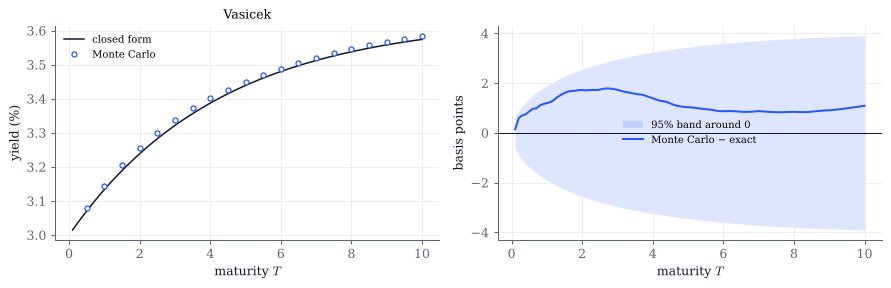

In [4]:
def monte_carlo(model="Vasicek", r0=0.03, kappa=0.15, theta=0.05, sigma=0.025, n_paths=20_000, seed=14):
    T, n = 10.0, 100
    if model == "Vasicek":
        t, _, I = vasicek_exact(r0, kappa, theta, sigma, T, n, n_paths=n_paths, seed=seed)
        closed = lambda x: vasicek_bond(r0, x, kappa, theta, sigma)
    else:
        s_cir = sigma / np.sqrt(theta)
        t, r = cir_exact(r0, kappa, theta, s_cir, T, n, n_paths=n_paths, seed=seed)
        I = integrated_rate(t, r)
        closed = lambda x: cir_bond(r0, x, kappa, theta, s_cir)
    P, se = mc_bond_prices(I[:, 1:])
    tau = t[1:]
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.3))
    ax.plot(tau, 100 * yields(closed(tau), tau), color=INK, lw=1.2, label="closed form")
    ax.plot(tau[4::5], 100 * yields(P, tau)[4::5], "o", ms=4, mfc="white", color=COBALT, label="Monte Carlo")
    ax.set(xlabel="maturity $T$", ylabel="yield (%)", title=model)
    ax.legend(fontsize=8)
    err = 1e4 * (yields(P, tau) - yields(closed(tau), tau))
    band = 1e4 * 1.96 * se / (P * tau)
    ax2.fill_between(tau, -band, band, color=COBALT, alpha=0.15, lw=0, label="95% band around 0")
    ax2.plot(tau, err, color=COBALT, label="Monte Carlo − exact")
    ax2.axhline(0, color=INK, lw=0.8)
    ax2.set(xlabel="maturity $T$", ylabel="basis points")
    ax2.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

monte_carlo()

In [5]:
interact(monte_carlo,
         model=Dropdown(options=["Vasicek", "CIR"], value="Vasicek", description="model"),
         r0=FloatSlider(value=0.03, min=0.0, max=0.1, step=0.005, continuous_update=False, readout_format=".3f", description="r₀"),
         kappa=FloatSlider(value=0.15, min=0.05, max=2.0, step=0.05, continuous_update=False, description="κ"),
         theta=FloatSlider(value=0.05, min=0.01, max=0.1, step=0.005, continuous_update=False, readout_format=".3f", description="θ"),
         sigma=FloatSlider(value=0.025, min=0.005, max=0.05, step=0.0025, continuous_update=False, readout_format=".4f", description="σ (Vasicek)"),
         n_paths=IntSlider(value=20_000, min=1_000, max=100_000, step=1_000, continuous_update=False, description="paths"),
         seed=IntSlider(value=14, min=0, max=100, continuous_update=False, description="seed"));

## 3. Negative rates in the Vasicek model

The Vasicek rate is normal, so $\mathbb Q(r_t<0)=N(-\mathbb E[r_t]/\mathrm{sd}(r_t))>0$ at every $t>0$, with the stationary
limit $N(-\theta\sqrt{2\kappa}/\sigma)$ (Proposition 14.8(iv)). Left: this probability over time, with a Monte Carlo
check. Right: the yield curve; when $\sigma^2>2\kappa^2\theta$ the long yield $R_\infty$ is negative, and bonds of long
maturity are worth more than their face value.

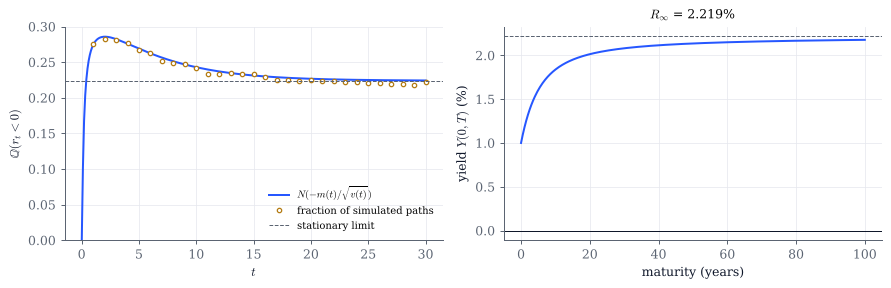

In [6]:
def negative(r0=0.01, kappa=0.2, theta=0.03, sigma=0.025):
    t = np.linspace(0.01, 30, 300)
    p = vasicek_negative_prob(t, r0, kappa, theta, sigma)
    ts, r, _ = vasicek_exact(r0, kappa, theta, sigma, 30.0, 30, n_paths=20_000, seed=3)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.3))
    ax.plot(t, p, color=COBALT, label="$N(-m(t)/\\sqrt{v(t)})$")
    ax.plot(ts[1:], (r[:, 1:] < 0).mean(0), "o", ms=3.5, mfc="white", color=GOLD, label="fraction of simulated paths")
    from scipy.stats import norm
    ax.axhline(norm.cdf(-theta * np.sqrt(2 * kappa) / sigma), color=GREY, ls="--", lw=0.8, label="stationary limit")
    ax.set(xlabel="$t$", ylabel="$\\mathbb{Q}(r_t<0)$", ylim=(0, None))
    ax.legend(fontsize=8)
    tau = np.linspace(0, 100, 401)
    ax2.plot(tau, 100 * vasicek_yield(r0, tau, kappa, theta, sigma), color=COBALT)
    R = vasicek_long_yield(kappa, theta, sigma)
    ax2.axhline(100 * R, color=GREY, ls="--", lw=0.8)
    ax2.axhline(0, color=INK, lw=0.8)
    ax2.set(xlabel="maturity (years)", ylabel="yield $Y(0,T)$ (%)", title=f"$R_\\infty$ = {100 * R:.3f}%")
    fig.tight_layout()
    plt.show()

negative()

In [7]:
# Explore: find sigma at which the long yield turns negative (sigma^2 = 2 kappa^2 theta).
interact(negative,
         r0=FloatSlider(value=0.01, min=-0.02, max=0.08, step=0.005, continuous_update=False, readout_format=".3f", description="r₀"),
         kappa=FloatSlider(value=0.2, min=0.02, max=2.0, step=0.02, continuous_update=False, description="κ"),
         theta=FloatSlider(value=0.03, min=0.0, max=0.08, step=0.005, continuous_update=False, readout_format=".3f", description="θ"),
         sigma=FloatSlider(value=0.025, min=0.002, max=0.08, step=0.002, continuous_update=False, readout_format=".3f", description="σ"));

## 4. The Feller condition in the CIR model

With $\nu=2\kappa\theta/\sigma^2\ge1$ the CIR rate never reaches $0$; with $\nu<1$ it keeps hitting $0$ and bouncing back
(Proposition 14.9(ii), Exercise 14.8). Left: exact paths. Middle: the histogram of $r_T$ from exact simulation and
from the Euler scheme with full truncation (the diffusion and drift use $\max(r,0)$), against the stationary gamma
density, which is unbounded at $0$ when $\nu<1$. Right: the fraction of Euler values that are negative, which the
exact process never produces.

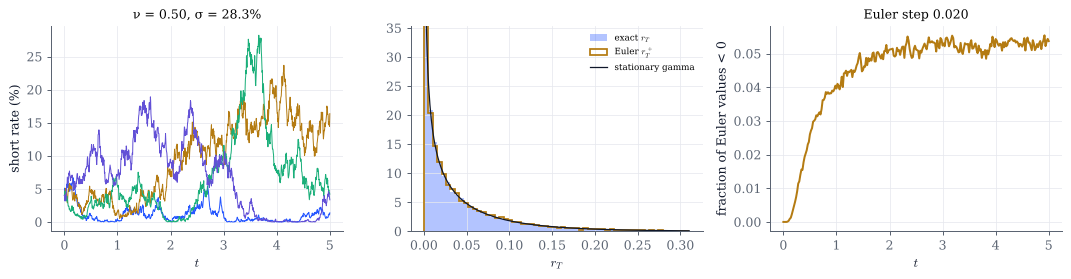

In [8]:
def feller(nu=0.5, kappa=0.5, theta=0.04, n_steps=250, seed=4):
    sigma = np.sqrt(2 * kappa * theta / nu)
    T, M = 5.0, 20_000
    t, r = cir_exact(theta, kappa, theta, sigma, T, 1000, n_paths=4, seed=seed)
    _, rx = cir_exact(theta, kappa, theta, sigma, T, 1, n_paths=M, seed=seed + 1)
    te, re = cir_euler(theta, kappa, theta, sigma, T, n_steps, n_paths=M, seed=seed + 2)
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
    axes[0].plot(t, 100 * r.T, lw=0.8)
    axes[0].set(xlabel="$t$", ylabel="short rate (%)", title=f"ν = {nu:.2f}, σ = {100 * sigma:.1f}%")
    shape, scale = cir_stationary(kappa, theta, sigma)
    x = np.linspace(1e-5, np.quantile(rx[:, -1], 0.995), 400)
    edges = np.linspace(0, x[-1], 61)
    axes[1].hist(rx[:, -1], bins=edges, density=True, color=COBALT, alpha=0.35, label="exact $r_T$")
    axes[1].hist(np.maximum(re[:, -1], 0), bins=edges, density=True, histtype="step", color=GOLD, lw=1.4, label="Euler $r_T^+$")
    axes[1].plot(x, gamma_law.pdf(x, shape, scale=scale), color=INK, lw=1.0, label="stationary gamma")
    axes[1].set(xlabel="$r_T$", ylim=(0, 3 * gamma_law.pdf(np.median(rx[:, -1]), shape, scale=scale)))
    axes[1].legend(fontsize=7)
    axes[2].plot(te, (re < 0).mean(0), color=GOLD)
    axes[2].set(xlabel="$t$", ylabel="fraction of Euler values < 0", title=f"Euler step {T / n_steps:.3f}")
    fig.tight_layout()
    plt.show()

feller()

In [9]:
# Explore: cross nu = 1; refine the Euler step and watch its negative values shrink but not vanish.
interact(feller,
         nu=FloatSlider(value=0.5, min=0.1, max=5.0, step=0.05, continuous_update=False, description="ν"),
         kappa=FloatSlider(value=0.5, min=0.05, max=3.0, step=0.05, continuous_update=False, description="κ"),
         theta=FloatSlider(value=0.04, min=0.005, max=0.1, step=0.005, continuous_update=False, readout_format=".3f", description="θ"),
         n_steps=IntSlider(value=250, min=25, max=2500, step=25, continuous_update=False, description="Euler steps"),
         seed=IntSlider(value=4, min=0, max=100, continuous_update=False, description="seed"));

## 5. Bond options and the forward measure

A call with expiry $T$ and strike $K$ on the bond maturing at $S>T$ is worth
$P(0,S)N(d_+)-KP(0,T)N(d_-)$ in the Vasicek model (Jamshidian's formula, Proposition 14.10). Under $\mathbb Q$ its Monte
Carlo price needs the discount factor, $\mathbb E^{\mathbb Q}[e^{-\int_0^Tr}(P(T,S)-K)^+]$; under the $T$-forward measure
$\mathbb Q^T$ only $r_T$ is needed, $P(0,T)\,\mathbb E^{\mathbb Q^T}[(P(T,S)-K)^+]$, and $r_T$ is normal with mean $f(0,T)$. Right:
the forward rate $f(0,T)$ is the expected short rate under $\mathbb Q^T$, not under $\mathbb Q$; the squares reweight
$\mathbb Q$-paths by the density $D_T/P(0,T)$ of $\mathbb Q^T$.

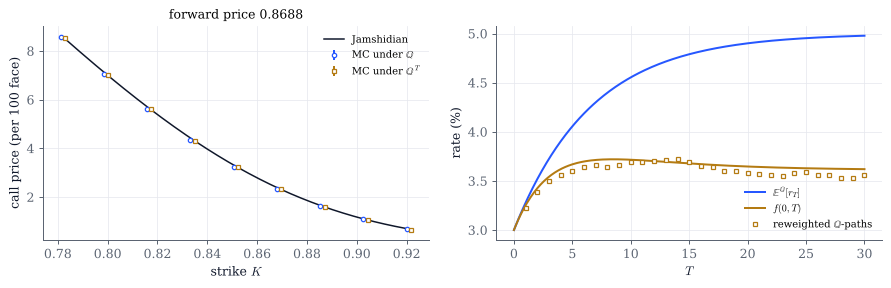

In [10]:
def bond_option(T=1.0, S=5.0, r0=0.03, kappa=0.15, theta=0.05, sigma=0.025, n_paths=40_000, seed=21):
    S = max(S, T + 0.25)
    PT = vasicek_bond(r0, T, kappa, theta, sigma)
    fwd = vasicek_bond(r0, S, kappa, theta, sigma) / PT
    strikes = fwd * np.linspace(0.9, 1.06, 9)
    _, r, I = vasicek_exact(r0, kappa, theta, sigma, T, 1, n_paths=n_paths, seed=seed)
    PTS_q = vasicek_bond(r[:, -1], S - T, kappa, theta, sigma)
    PTS_f = vasicek_bond(vasicek_forward_measure_rT(r0, T, kappa, theta, sigma, n_paths, seed=seed + 1), S - T, kappa, theta, sigma)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.3))
    fine = np.linspace(strikes[0], strikes[-1], 200)
    ax.plot(fine, 100 * vasicek_bond_option(fine, T, S, r0, kappa, theta, sigma), color=INK, lw=1.2, label="Jamshidian")
    for k, (v, c, lab) in enumerate((
            (np.exp(-I[:, -1])[None, :] * np.maximum(PTS_q[None, :] - strikes[:, None], 0), COBALT, "MC under $\\mathbb{Q}$"),
            (PT * np.maximum(PTS_f[None, :] - strikes[:, None], 0), GOLD, "MC under $\\mathbb{Q}^T$"))):
        est, se = v.mean(1), v.std(1, ddof=1) / np.sqrt(n_paths)
        ax.errorbar(strikes * (1 + (k - 0.5) * 0.002), 100 * est, yerr=196 * se, ls="none", marker="os"[k], ms=3.5,
                    mfc="white", color=c, label=lab)
    ax.set(xlabel="strike $K$", ylabel="call price (per 100 face)", title=f"forward price {fwd:.4f}")
    ax.legend(fontsize=8)
    Tm = 30.0
    t, r, I = vasicek_exact(r0, kappa, theta, sigma, Tm, 30, n_paths=20_000, seed=seed + 2)
    w = np.exp(-I) / np.exp(-I).mean(0)
    g = np.linspace(0, Tm, 301)
    ax2.plot(g, 100 * vasicek_mean(g, r0, kappa, theta), color=COBALT, label="$\\mathbb{E}^{\\mathbb{Q}}[r_T]$")
    ax2.plot(g, 100 * vasicek_forward(r0, g, kappa, theta, sigma), color=GOLD, label="$f(0,T)$")
    ax2.plot(t[1:], 100 * (w * r).mean(0)[1:], "s", ms=3.5, mfc="white", color=GOLD, label="reweighted $\\mathbb{Q}$-paths")
    ax2.set(xlabel="$T$", ylabel="rate (%)")
    ax2.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

bond_option()

In [11]:
interact(bond_option,
         T=FloatSlider(value=1.0, min=0.25, max=5.0, step=0.25, continuous_update=False, description="expiry T"),
         S=FloatSlider(value=5.0, min=0.5, max=20.0, step=0.5, continuous_update=False, description="bond S"),
         r0=FloatSlider(value=0.03, min=-0.01, max=0.1, step=0.005, continuous_update=False, readout_format=".3f", description="r₀"),
         kappa=FloatSlider(value=0.15, min=0.02, max=2.0, step=0.02, continuous_update=False, description="κ"),
         theta=FloatSlider(value=0.05, min=0.0, max=0.1, step=0.005, continuous_update=False, readout_format=".3f", description="θ"),
         sigma=FloatSlider(value=0.025, min=0.002, max=0.06, step=0.002, continuous_update=False, readout_format=".3f", description="σ"),
         n_paths=IntSlider(value=40_000, min=2_000, max=200_000, step=2_000, continuous_update=False, description="paths"),
         seed=IntSlider(value=21, min=0, max=100, continuous_update=False, description="seed"));

## 6. A homework simulation: Vasicek against CIR

The IEOR 222 homework on rate models simulated both models with the Euler scheme, $\kappa=1$, $\theta=0.1$, $\sigma=0.3$,
$T=10$, $10^4$ time steps and $10^3$ paths (in the homework, $\alpha$, $\beta$, $\sigma$; the starting value was not given,
we take $r_0=\theta$). With these parameters the Vasicek rate is negative a third of the time in the long run
($N(-\theta\sqrt{2\kappa}/\sigma)=N(-0.47)\approx0.32$), while the CIR rate stays nonnegative (the Feller ratio is
$2\kappa\theta/\sigma^2=2.2$). Both averages at $T$ are close to $\theta$, whatever $r_0$: the mean
$\theta+(r_0-\theta)e^{-\kappa T}$ is the same in the two models (Exercise 14.4). The same Brownian increments drive both.

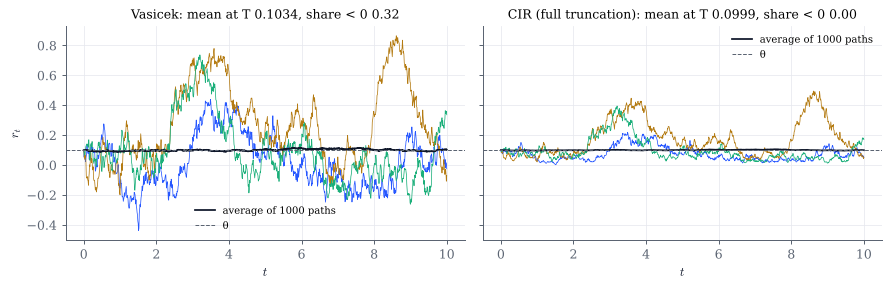

In [12]:
def homework(kappa=1.0, theta=0.1, sigma=0.3, r0=0.1, seed=8):
    T, n, M = 10.0, 10_000, 1_000
    dW = np.random.default_rng(seed).normal(0, np.sqrt(T / n), (M, n))
    t, rv = vasicek_euler(r0, kappa, theta, sigma, T, n, dW=dW)
    _, rc = cir_euler(r0, kappa, theta, sigma, T, n, dW=dW)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.3), sharey=True)
    for a, X, name in ((ax, rv, "Vasicek"), (ax2, rc, "CIR (full truncation)")):
        a.plot(t[::10], X[:3, ::10].T, lw=0.6)
        a.plot(t, X.mean(0), color=INK, lw=1.4, label="average of 1000 paths")
        a.axhline(theta, color=GREY, ls="--", lw=0.8, label="θ")
        a.set(xlabel="$t$", title=f"{name}: mean at T {X[:, -1].mean():.4f}, share < 0 {np.mean(X[:, -1] < 0):.2f}")
        a.legend(fontsize=8)
    ax.set_ylabel("$r_t$")
    fig.tight_layout()
    plt.show()

homework()

In [13]:
# Explore: the homework asked about the effect of kappa; try very large values.
interact(homework,
         kappa=FloatSlider(value=1.0, min=0.05, max=20.0, step=0.05, continuous_update=False, description="κ (α)"),
         theta=FloatSlider(value=0.1, min=0.0, max=0.3, step=0.01, continuous_update=False, description="θ (β)"),
         sigma=FloatSlider(value=0.3, min=0.01, max=1.0, step=0.01, continuous_update=False, description="σ"),
         r0=FloatSlider(value=0.1, min=0.0, max=0.5, step=0.01, continuous_update=False, description="r₀"),
         seed=IntSlider(value=8, min=0, max=100, continuous_update=False, description="seed"));

## Things to try

- In section 1, set $r_0$ just inside the humped range and lengthen the horizon: where is the hump, and how high is it?
  Is the CIR curve humped for the same $r_0$?
- In section 2, set $\sigma$ (and so the CIR volatility) large, with few paths. Which model's Monte Carlo yields are
  noisier at long maturities, and why?
- In section 3, set $\theta=0$. What is the stationary probability of a negative rate, and why does it not depend on $\sigma$?
- In section 4, take $\nu$ slightly below and slightly above $1$. Can you tell the two cases apart from the paths? From
  the histogram? How small must the Euler step be before the negative values stop mattering for $r_T$?
- In section 5, make the bond option far out of the money. Which Monte Carlo estimator has the larger relative error?
  Move $\sigma$ and watch the gap between $\mathbb E^{\mathbb Q}[r_T]$ and $f(0,T)$, which is $\sigma^2B(T)^2/2$.
- In section 6, take $\kappa$ very large. What happens to the paths and to their spread, and what does the stationary
  variance $\sigma^2/(2\kappa)$ predict?